# 02. 분할 · 학습 · 평가 — AI 생성 이미지 판별기

01번 노트북에서 모은 데이터로 **베이스라인(ResNet-50)** 과 **제안 모델(CLIP ViT-L/14 + 분류 헤드)** 을 학습하고,
테스트셋에서 비교합니다. README `## 3 ~ ## 5` 에 들어갈 표와 그림이 전부 `/kaggle/working/results` 에 저장돼요.

## 실행 전 설정
1. **Accelerator: GPU T4 x2**, **Internet: On**
2. **Add Input** → **Your Work / Datasets** 에서 01번 출력으로 만든 내 데이터셋 추가 (예: `ai-vs-real-collected`)

## 구성
| 단계 | README | 평가 항목 |
|---|---|---|
| 1. 분할 (70/15/15, seed=42, 처음 보는 생성기는 테스트 전용) | ## 3 | B3 |
| 2. 전처리·증강 시각화 | ## 3 | B2 |
| 3. 베이스라인 ResNet-50 전이학습 | ## 4 | C1 |
| 4. 제안 모델 CLIP ViT-L/14 특징 + MLP 헤드 | ## 4 | C1, C2 |
| 5. 테스트 비교표 · 혼동행렬 · 학습곡선 · 오류 사례 · 생성기별 정확도 | ## 5 | C3, C4 |
| 6. 가중치 저장 (+ HF Hub 업로드) | ## 8 | E2, D1 |

> ⏱ 예상 시간: 베이스라인 15~25분, CLIP 특징 추출 10~20분, 나머지 수 분.
> Save Version → Save & Run All 로 돌리면 노트북을 덮어도 됩니다.

## 0. 설정

In [6]:
import os, json, time, random, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

# 01번에서 만든 데이터셋 위치 자동 찾기 (manifest.csv 가 있는 폴더)
MANIFEST = next(Path('/kaggle/input').rglob('manifest.csv'), None)
if MANIFEST is None:   # data.zip 으로 저장한 경우 → 압축 풀기
    z = next(Path('/kaggle/input').rglob('data.zip'))
    print('압축 해제 중:', z)
    import zipfile; zipfile.ZipFile(z).extractall('/kaggle/working/unzipped')
    MANIFEST = next(Path('/kaggle/working/unzipped').rglob('manifest.csv'))
DATA = MANIFEST.parent
print('데이터 위치:', DATA)

RES = Path('/kaggle/working/results'); RES.mkdir(parents=True, exist_ok=True)
WTS = Path('/kaggle/working/weights'); WTS.mkdir(parents=True, exist_ok=True)

LABEL2ID = {'real': 0, 'fake': 1}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
NUM_WORKERS = 4

device: cuda Tesla T4
데이터 위치: /kaggle/input/datasets/hyunjae11/ai-vs-real-collected/data/data


## 1. 데이터 분할 (B3)
- `split_hint == 'pool'` → **train 70% / val 15% / test 15%**, `seed=42`, 라벨과 출처를 함께 고려한 층화 분할
- `split_hint == 'unseen'` (FLUX · GPT-4o · SDXL-Turbo 직접 생성 · 내 폰 사진) → **학습에 전혀 쓰지 않는 별도 테스트셋**

In [2]:
df = pd.read_csv(MANIFEST)
df['y'] = df['label'].map(LABEL2ID)
df = df[df['path'].map(lambda p: (DATA / p).exists())].reset_index(drop=True)
print(f'전체 {len(df):,}장')

pool = df[df.split_hint == 'pool'].copy()
unseen = df[df.split_hint == 'unseen'].copy()
strat = pool['label'] + '_' + pool['source']

train_df, tmp = train_test_split(pool, test_size=0.30, stratify=strat, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp['label'] + '_' + tmp['source'], random_state=SEED)
train_df['split'], val_df['split'], test_df['split'], unseen['split'] = 'train', 'val', 'test', 'test_unseen'

splits = pd.concat([train_df, val_df, test_df, unseen]).reset_index(drop=True)
splits.to_csv(RES / 'splits.csv', index=False)

tbl = splits.groupby(['split', 'label']).size().unstack(fill_value=0)
tbl['total'] = tbl.sum(1)
display(tbl)
tbl.to_csv(RES / 'split_table.csv')
display(splits.groupby(['split', 'source']).size().unstack(fill_value=0).T)

전체 39,366장


label,fake,real,total
split,,,
test,3150,2380,5530
test_unseen,2500,0,2500
train,14700,11106,25806
val,3150,2380,5530


split,test,test_unseen,train,val
source,,,,
elsa_fake,900,0,4200,900
elsa_real,130,0,606,130
gpt4o_unseen,0,1000,0,0
kaggle_fake,2250,0,10500,2250
kaggle_real,2250,0,10500,2250
sdxl_turbo,0,1500,0,0


## 2. 전처리 · 증강 (B2)
01번에서 이미 한 전처리: **① 손상·너무 작은 이미지 제거 ② MD5 중복 제거 ③ 256×256 정사각 리사이즈 + JPEG(90) 재압축 통일**
여기서 추가하는 전처리: **④ 데이터 증강(랜덤 크롭·좌우반전·색상 변화·블러) ⑤ 정규화(모델별 평균·표준편차)**

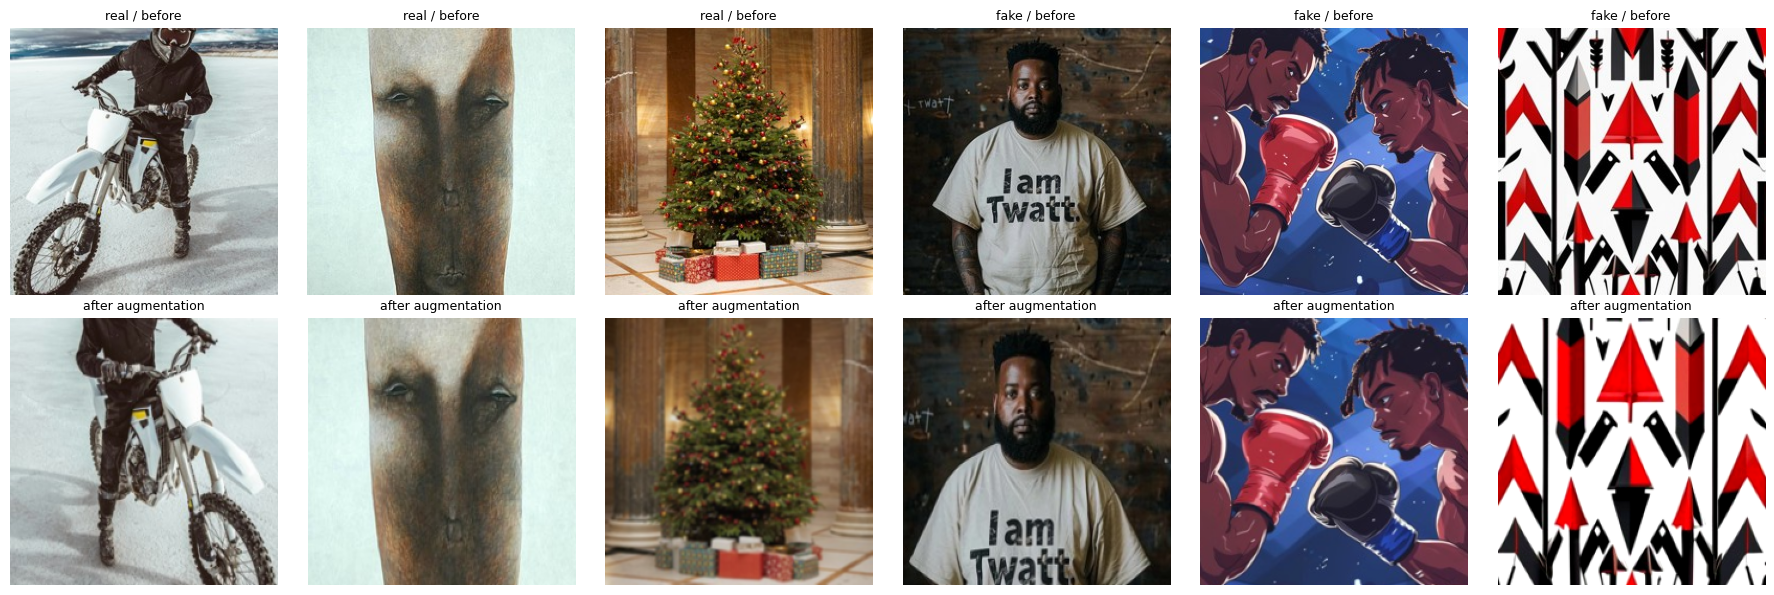

In [7]:
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLIP_MEAN, CLIP_STD = (0.4815, 0.4578, 0.4082), (0.2686, 0.2613, 0.2758)

def make_tf(train, mean, std):
    if train:
        return T.Compose([
            T.RandomResizedCrop(224, scale=(0.6, 1.0)),
            T.RandomHorizontalFlip(),
            T.RandomApply([T.ColorJitter(0.2, 0.2, 0.2, 0.02)], p=0.5),
            T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.5))], p=0.2),
            T.ToTensor(), T.Normalize(mean, std)])
    return T.Compose([T.CenterCrop(224), T.ToTensor(), T.Normalize(mean, std)])

class ImgDS(Dataset):
    def __init__(self, frame, tf):
        self.p = frame['path'].tolist(); self.y = frame['y'].tolist(); self.tf = tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(DATA / self.p[i]).convert('RGB')), self.y[i]

# 증강 전·후 예시 그림
def denorm(t, mean, std):
    return (t * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]).clamp(0, 1).permute(1, 2, 0)

ex = train_df.groupby('label').head(3)
aug = make_tf(True, IMNET_MEAN, IMNET_STD)
fig, ax = plt.subplots(2, len(ex), figsize=(3 * len(ex), 6))
for i, (_, r) in enumerate(ex.iterrows()):
    im = Image.open(DATA / r.path).convert('RGB')
    ax[0, i].imshow(im); ax[0, i].set_title(f'{r.label} / before', fontsize=9)
    ax[1, i].imshow(denorm(aug(im), IMNET_MEAN, IMNET_STD)); ax[1, i].set_title('after augmentation', fontsize=9)
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.savefig(RES / 'augmentation_examples.png', dpi=120); plt.show()

## 3. 베이스라인 — ResNet-50 전이학습 (C1)
ImageNet 사전학습 가중치에서 시작해 전체 층을 파인튜닝합니다. AMP(혼합 정밀도)로 T4에서도 빠르게 학습해요.
val F1이 가장 좋은 epoch의 가중치를 저장합니다.

In [8]:
EPOCHS_R50, BS, LR = 4, 64, 1e-4

def loaders(mean, std, bs=BS):
    tr = DataLoader(ImgDS(train_df, make_tf(True, mean, std)), bs, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    mk = lambda d: DataLoader(ImgDS(d, make_tf(False, mean, std)), bs * 2, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    return tr, mk(val_df), mk(test_df), (mk(unseen) if len(unseen) else None)

@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        with torch.autocast('cuda', dtype=torch.float16):
            P.append(torch.softmax(model(x.to(DEVICE)).float(), 1)[:, 1].cpu())
        Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

seed_all()
r50 = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
r50.fc = nn.Linear(r50.fc.in_features, 2)
r50 = r50.to(DEVICE)

tr_dl, va_dl, te_dl, un_dl = loaders(IMNET_MEAN, IMNET_STD)
opt = torch.optim.AdamW(r50.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS_R50 * len(tr_dl))
scaler = torch.cuda.amp.GradScaler()

hist_r50, best = [], -1
for ep in range(1, EPOCHS_R50 + 1):
    r50.train(); tl, tc, tn = 0, 0, 0; t0 = time.time()
    for x, y in tqdm(tr_dl, desc=f'R50 ep{ep}', leave=False):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.float16):
            out = r50(x); loss = F.cross_entropy(out, y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
    vp, vy = predict(r50, va_dl)
    vloss = F.binary_cross_entropy(torch.tensor(vp).clamp(1e-6, 1 - 1e-6), torch.tensor(vy).float()).item()
    row = dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss,
               val_acc=accuracy_score(vy, vp > .5), val_f1=f1_score(vy, vp > .5), sec=time.time() - t0)
    hist_r50.append(row); print({k: round(v, 4) for k, v in row.items()})
    if row['val_f1'] > best:
        best = row['val_f1']; torch.save(r50.state_dict(), WTS / 'resnet50_best.pt')
pd.DataFrame(hist_r50).to_csv(RES / 'log_resnet50.csv', index=False)
r50.load_state_dict(torch.load(WTS / 'resnet50_best.pt')); print('best val F1:', best)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 217MB/s] 
/tmp/ipykernel_49/1352256829.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


R50 ep1:   0%|          | 0/403 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.4689, 'train_acc': 0.7683, 'val_loss': 0.306, 'val_acc': 0.8664, 'val_f1': 0.8898, 'sec': 946.6955}


R50 ep2:   0%|          | 0/403 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.2412, 'train_acc': 0.9022, 'val_loss': 0.2192, 'val_acc': 0.9078, 'val_f1': 0.9208, 'sec': 136.0943}


R50 ep3:   0%|          | 0/403 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.1485, 'train_acc': 0.9416, 'val_loss': 0.2039, 'val_acc': 0.9224, 'val_f1': 0.9339, 'sec': 135.1859}


R50 ep4:   0%|          | 0/403 [00:00<?, ?it/s]

{'epoch': 4, 'train_loss': 0.0886, 'train_acc': 0.9687, 'val_loss': 0.2027, 'val_acc': 0.9224, 'val_f1': 0.9338, 'sec': 134.7551}
best val F1: 0.933928846450023


## 4. 제안 모델 — CLIP ViT-L/14 특징 + MLP 헤드 (C1, C2)
**선정 이유:** CLIP은 4억 쌍의 이미지·텍스트로 사전학습돼 이미지 특징이 매우 일반적입니다.
이 특징 공간에서 real/fake 경계를 학습하면 **학습에 없던 생성기에도 잘 일반화**된다는 연구 결과가 있어요
(Ojha et al., *Towards Universal Fake Image Detectors that Generalize Across Generative Models*, CVPR 2023).

방식: ① CLIP 이미지 인코더(약 3억 파라미터)는 **고정**하고 특징(768차원)을 한 번 추출 → ② 그 위에 MLP 헤드를 학습.
학습 데이터는 좌우반전을 넣은 2가지 버전으로 추출해 증강 효과를 줍니다.

In [11]:
from transformers import CLIPVisionModelWithProjection

CLIP_ID = 'openai/clip-vit-large-patch14'
clip = CLIPVisionModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=torch.float16).to(DEVICE).eval()

@torch.no_grad()
def extract(frame, flip=False, bs=128):
    tf = T.Compose([T.CenterCrop(224)] + ([T.RandomHorizontalFlip(1.0)] if flip else []) +
                   [T.ToTensor(), T.Normalize(CLIP_MEAN, CLIP_STD)])
    dl = DataLoader(ImgDS(frame, tf), bs, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    feats = []
    for x, _ in tqdm(dl, desc='CLIP features', leave=False):
        feats.append(clip(pixel_values=x.to(DEVICE, dtype=torch.float16)).image_embeds.float().cpu())
    return torch.cat(feats)

t0 = time.time()
Xtr = torch.cat([extract(train_df), extract(train_df, flip=True)]); Ytr = torch.tensor(train_df.y.tolist() * 2)
Xva, Yva = extract(val_df), torch.tensor(val_df.y.values)
Xte, Yte = extract(test_df), torch.tensor(test_df.y.values)
Xun = extract(unseen) if len(unseen) else None
print(f'특징 추출 완료: {time.time() - t0:.0f}초, train {tuple(Xtr.shape)}')
torch.save(dict(Xtr=Xtr, Ytr=Ytr, Xva=Xva, Yva=Yva, Xte=Xte, Yte=Yte, Xun=Xun), '/kaggle/working/clip_feats.pt')

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{

CLIP features:   0%|          | 0/202 [00:00<?, ?it/s]

CLIP features:   0%|          | 0/202 [00:00<?, ?it/s]

CLIP features:   0%|          | 0/44 [00:00<?, ?it/s]

CLIP features:   0%|          | 0/44 [00:00<?, ?it/s]

CLIP features:   0%|          | 0/20 [00:00<?, ?it/s]

특징 추출 완료: 897초, train (51612, 768)


In [12]:
class Head(nn.Module):
    def __init__(self, d=768, h=512, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, 2))
    def forward(self, x): return self.net(F.normalize(x, dim=-1))

seed_all()
head = Head(Xtr.shape[1]).to(DEVICE)
EPOCHS_H = 30
opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_H)
tr = DataLoader(torch.utils.data.TensorDataset(Xtr, Ytr), 512, shuffle=True)

@torch.no_grad()
def head_prob(X):
    head.eval(); return torch.softmax(head(X.to(DEVICE)), 1)[:, 1].cpu().numpy()

hist_clip, best = [], -1
for ep in range(1, EPOCHS_H + 1):
    head.train(); tl, tc, tn = 0, 0, 0
    for x, y in tr:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = head(x); loss = F.cross_entropy(out, y, label_smoothing=0.05)
        opt.zero_grad(); loss.backward(); opt.step()
        tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
    sched.step()
    vp = head_prob(Xva); vy = Yva.numpy()
    vloss = F.binary_cross_entropy(torch.tensor(vp).clamp(1e-6, 1 - 1e-6), torch.tensor(vy).float()).item()
    row = dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss,
               val_acc=accuracy_score(vy, vp > .5), val_f1=f1_score(vy, vp > .5))
    hist_clip.append(row)
    if ep % 5 == 0 or ep == 1: print({k: round(v, 4) for k, v in row.items()})
    if row['val_f1'] > best:
        best = row['val_f1']; torch.save(head.state_dict(), WTS / 'clip_head_best.pt')
pd.DataFrame(hist_clip).to_csv(RES / 'log_clip_head.csv', index=False)
head.load_state_dict(torch.load(WTS / 'clip_head_best.pt')); print('best val F1:', best)

{'epoch': 1, 'train_loss': 0.3021, 'train_acc': 0.9072, 'val_loss': 0.1943, 'val_acc': 0.9297, 'val_f1': 0.9386}
{'epoch': 5, 'train_loss': 0.1527, 'train_acc': 0.9939, 'val_loss': 0.1526, 'val_acc': 0.9445, 'val_f1': 0.9517}
{'epoch': 10, 'train_loss': 0.1305, 'train_acc': 0.9997, 'val_loss': 0.1592, 'val_acc': 0.9401, 'val_f1': 0.9475}
{'epoch': 15, 'train_loss': 0.1259, 'train_acc': 1.0, 'val_loss': 0.1605, 'val_acc': 0.9421, 'val_f1': 0.9493}
{'epoch': 20, 'train_loss': 0.1241, 'train_acc': 1.0, 'val_loss': 0.1608, 'val_acc': 0.941, 'val_f1': 0.9484}
{'epoch': 25, 'train_loss': 0.1233, 'train_acc': 1.0, 'val_loss': 0.1605, 'val_acc': 0.9398, 'val_f1': 0.9474}
{'epoch': 30, 'train_loss': 0.123, 'train_acc': 1.0, 'val_loss': 0.1601, 'val_acc': 0.9405, 'val_f1': 0.948}
best val F1: 0.952003801679075


## 5. 테스트셋 평가 · 비교 (C3) — 최종 모델 선정
지표: **Accuracy, Precision, Recall, F1, ROC-AUC** (양성 = fake)

In [13]:
def metrics(y, p, thr=0.5):
    yh = (p > thr).astype(int)
    out = dict(Accuracy=accuracy_score(y, yh), Precision=precision_score(y, yh, zero_division=0),
               Recall=recall_score(y, yh, zero_division=0), F1=f1_score(y, yh, zero_division=0))
    out['ROC-AUC'] = roc_auc_score(y, p) if len(set(y)) > 1 else np.nan
    return out

p_r50_te, y_te = predict(r50, te_dl)
p_clip_te = head_prob(Xte)
assert (y_te == Yte.numpy()).all()

rows = [dict(model='Baseline: ResNet-50', set='test', **metrics(y_te, p_r50_te)),
        dict(model='Proposed: CLIP ViT-L/14 + MLP', set='test', **metrics(y_te, p_clip_te))]

# 처음 보는 생성기 + 같은 수의 test real 을 섞어 F1/AUC 계산
if un_dl is not None:
    p_r50_un, y_un = predict(r50, un_dl); p_clip_un = head_prob(Xun)
    real_te = np.where(y_te == 0)[0]
    n_fake_un = int((y_un == 1).sum())
    pick = np.random.RandomState(SEED).choice(real_te, min(len(real_te), max(n_fake_un, 1)), replace=False)
    for name, pu, pt in (('Baseline: ResNet-50', p_r50_un, p_r50_te), ('Proposed: CLIP ViT-L/14 + MLP', p_clip_un, p_clip_te)):
        y_mix = np.concatenate([y_un, y_te[pick]]); p_mix = np.concatenate([pu, pt[pick]])
        rows.append(dict(model=name, set='unseen generators (+test real)', **metrics(y_mix, p_mix)))

res = pd.DataFrame(rows)
display(res.style.format({c: '{:.4f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}).highlight_max(subset=['F1', 'ROC-AUC'], color='#cde'))
res.to_csv(RES / 'results_table.csv', index=False)
try:
    print(res.round(4).to_markdown(index=False))   # README에 그대로 붙여넣기
except ImportError:
    print(res.round(4).to_string(index=False))

,model,set,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline: ResNet-50,test,0.9105,0.9002,0.9479,0.9235,0.9725
1,Proposed: CLIP ViT-L/14 + MLP,test,0.9436,0.9437,0.9581,0.9509,0.9844
2,Baseline: ResNet-50,unseen generators (+test real),0.8314,0.8585,0.8032,0.8299,0.9111
3,Proposed: CLIP ViT-L/14 + MLP,unseen generators (+test real),0.8068,0.9061,0.6948,0.7865,0.9220


| model                         | set                            |   Accuracy |   Precision |   Recall |     F1 |   ROC-AUC |
|:------------------------------|:-------------------------------|-----------:|------------:|---------:|-------:|----------:|
| Baseline: ResNet-50           | test                           |     0.9105 |      0.9002 |   0.9479 | 0.9235 |    0.9725 |
| Proposed: CLIP ViT-L/14 + MLP | test                           |     0.9436 |      0.9437 |   0.9581 | 0.9509 |    0.9844 |
| Baseline: ResNet-50           | unseen generators (+test real) |     0.8314 |      0.8585 |   0.8032 | 0.8299 |    0.9111 |
| Proposed: CLIP ViT-L/14 + MLP | unseen generators (+test real) |     0.8068 |      0.9061 |   0.6948 | 0.7865 |    0.922  |


## 6. 결과 분석 (C4) — 학습곡선 · 혼동행렬 · ROC · 생성기별 정확도 · 오류 사례

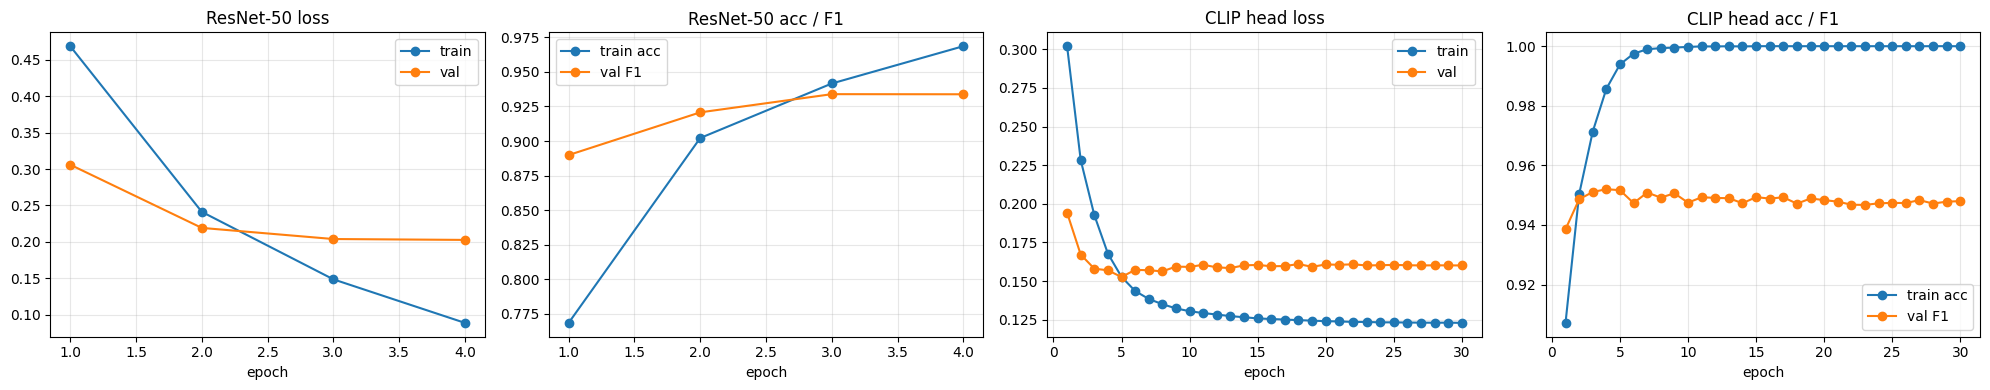

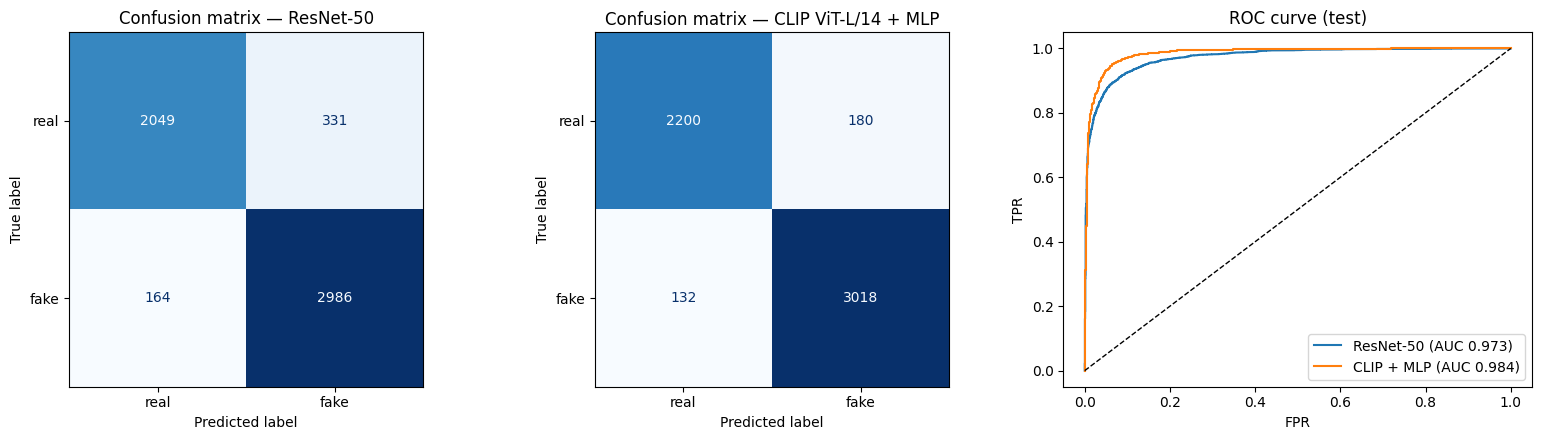

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for h, name in ((pd.DataFrame(hist_r50), 'ResNet-50'), (pd.DataFrame(hist_clip), 'CLIP head')):
    ax[0 if name == 'ResNet-50' else 2].plot(h.epoch, h.train_loss, 'o-', label='train'); ax[0 if name == 'ResNet-50' else 2].plot(h.epoch, h.val_loss, 'o-', label='val')
    ax[1 if name == 'ResNet-50' else 3].plot(h.epoch, h.train_acc, 'o-', label='train acc'); ax[1 if name == 'ResNet-50' else 3].plot(h.epoch, h.val_f1, 'o-', label='val F1')
for a, t in zip(ax, ['ResNet-50 loss', 'ResNet-50 acc / F1', 'CLIP head loss', 'CLIP head acc / F1']):
    a.set_title(t); a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / 'learning_curves.png', dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (name, p) in zip(ax[:2], (('ResNet-50', p_r50_te), ('CLIP ViT-L/14 + MLP', p_clip_te))):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p > .5), display_labels=['real', 'fake']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(f'Confusion matrix — {name}')
for name, p in (('ResNet-50', p_r50_te), ('CLIP + MLP', p_clip_te)):
    fpr, tpr, _ = roc_curve(y_te, p); ax[2].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_te, p):.3f})')
ax[2].plot([0, 1], [0, 1], 'k--', lw=1); ax[2].set_title('ROC curve (test)'); ax[2].set_xlabel('FPR'); ax[2].set_ylabel('TPR'); ax[2].legend()
plt.tight_layout(); plt.savefig(RES / 'confusion_roc.png', dpi=120); plt.show()

ResNet-50 acc  CLIP acc     n
split       source       label                               
test        elsa_fake    fake           0.939     0.958   900
            elsa_real    real           0.438     0.577   130
            kaggle_fake  fake           0.952     0.958  2250
            kaggle_real  real           0.885     0.944  2250
test_unseen gpt4o_unseen fake           0.809     0.863  1000
            sdxl_turbo   fake           0.799     0.583  1500

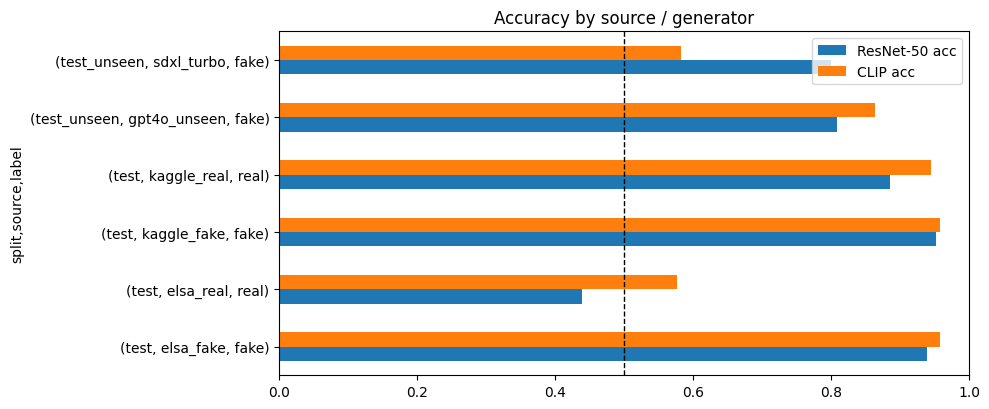

In [15]:
# 출처(생성기)별 정확도 — 처음 보는 생성기에서 두 모델 차이가 핵심
ev = test_df.assign(p_r50=p_r50_te, p_clip=p_clip_te)
if un_dl is not None:
    ev = pd.concat([ev, unseen.assign(p_r50=p_r50_un, p_clip=p_clip_un)])
ev['ok_r50'] = (ev.p_r50 > .5).astype(int) == ev.y
ev['ok_clip'] = (ev.p_clip > .5).astype(int) == ev.y
by_src = ev.groupby(['split', 'source', 'label'])[['ok_r50', 'ok_clip']].mean().rename(
    columns={'ok_r50': 'ResNet-50 acc', 'ok_clip': 'CLIP acc'})
by_src['n'] = ev.groupby(['split', 'source', 'label']).size()
display(by_src.round(3)); by_src.to_csv(RES / 'accuracy_by_source.csv')

by_src[['ResNet-50 acc', 'CLIP acc']].plot.barh(figsize=(10, 0.45 * len(by_src) + 1.5))
plt.axvline(.5, color='k', ls='--', lw=1); plt.xlim(0, 1); plt.title('Accuracy by source / generator')
plt.tight_layout(); plt.savefig(RES / 'accuracy_by_source.png', dpi=120); plt.show()

CLIP 오답 1075장 / 8030장


/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 54032 (\N{HANGUL SYLLABLE PAN}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 51667 (\N{HANGUL SYLLABLE JIS}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 50577 (\N{HANGUL SYLLABLE YANG}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/310417

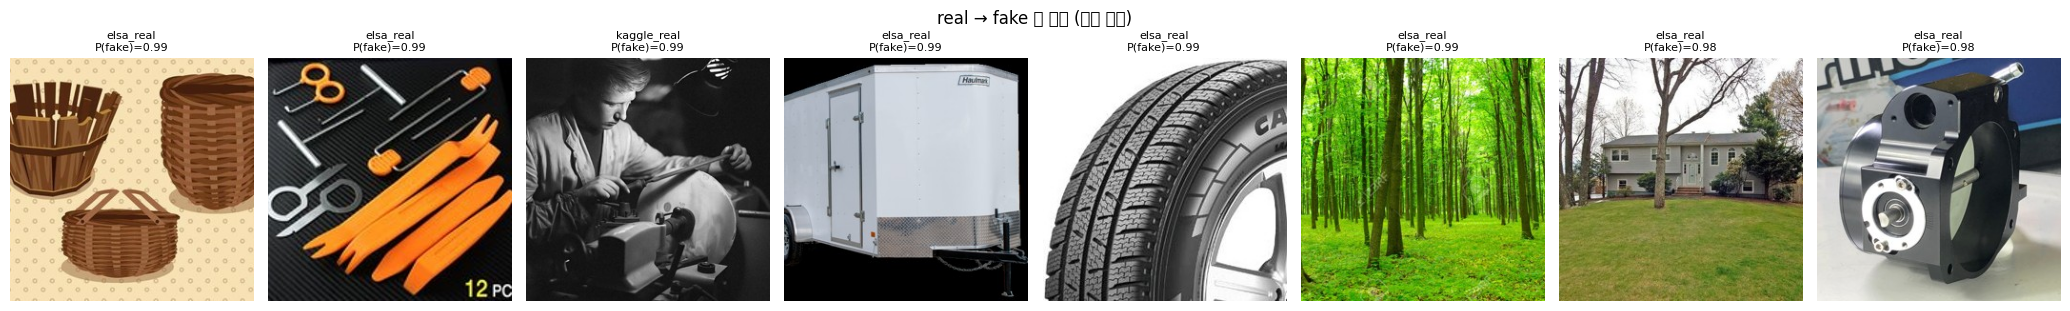

/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 45459 (\N{HANGUL SYLLABLE NOH}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:12: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout()
/tmp/ipykernel_49/3104177174.py:13: UserWarning: Glyph 45459 (\N{HANGUL SYLLABLE NOH}) missing from font(s) DejaVu Sans.
  plt.savefig(RES / f'errors_{ID2LABEL[lb]}.png', dpi=120); plt.show()
/tmp/ipykernel_49/3104177174.py:13: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  plt.savefig(RES / f'errors_{ID2LABEL[lb]}.png', dpi=120); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45459 (\N{HANGUL SYLLABLE NOH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 

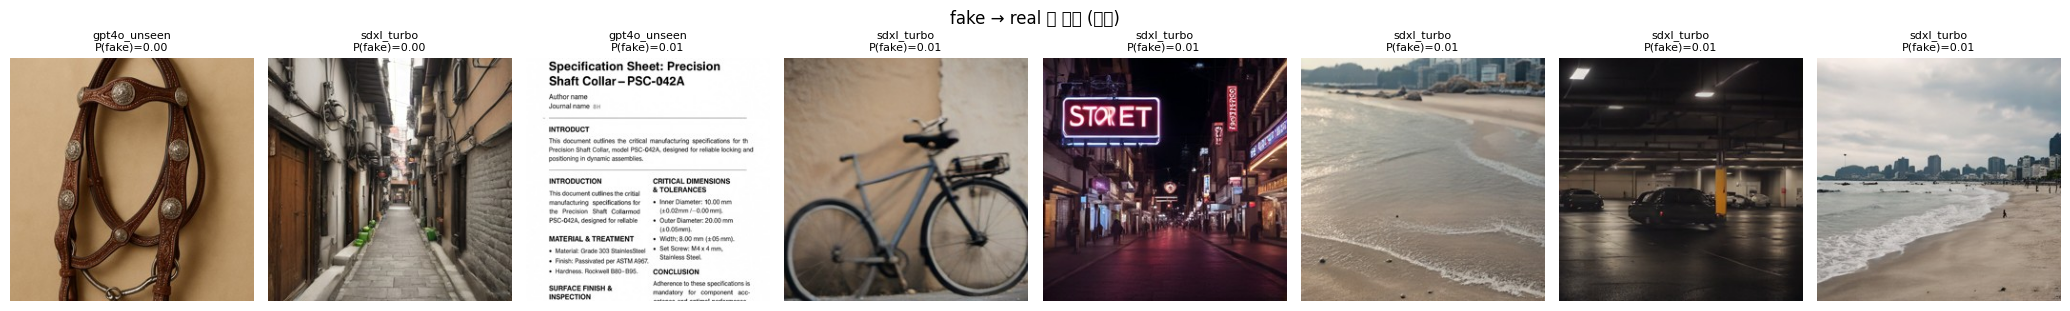

In [16]:
# 오류 사례 — 최종 모델(CLIP)이 가장 확신하며 틀린 이미지
ev['err_conf'] = np.where(ev.y == 1, 1 - ev.p_clip, ev.p_clip)
wrong = ev[~ev.ok_clip].sort_values('err_conf', ascending=False)
print(f'CLIP 오답 {len(wrong)}장 / {len(ev)}장')
for lb, title in ((0, 'real → fake 로 오판 (거짓 양성)'), (1, 'fake → real 로 오판 (놓침)')):
    w = wrong[wrong.y == lb].head(8)
    if not len(w): continue
    fig, ax = plt.subplots(1, len(w), figsize=(2.6 * len(w), 3.2), squeeze=False)
    for a, (_, r) in zip(ax[0], w.iterrows()):
        a.imshow(Image.open(DATA / r.path)); a.axis('off')
        a.set_title(f'{r.source}\nP(fake)={r.p_clip:.2f}', fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(RES / f'errors_{ID2LABEL[lb]}.png', dpi=120); plt.show()

## 7. 가중치 저장 · 업로드 (D1, E2)
- `weights/resnet50_best.pt` (약 95MB), `weights/clip_head_best.pt` (약 2MB), `weights/config.json`
- 서비스 앱은 **CLIP 인코더(공개 가중치) + 내가 학습한 헤드(`clip_head_best.pt`)** 를 불러와 추론합니다.
- HF Hub 업로드: Kaggle 상단 **Add-ons → Secrets** 에 `HF_TOKEN`(write 권한) 을 등록한 뒤 아래 셀을 실행하세요.
  **토큰을 코드에 직접 쓰지 마세요** (API Key 업로드 금지 규정).

In [17]:
best_name = res[res.set == 'test'].sort_values('F1', ascending=False).iloc[0].model
config = dict(final_model=best_name, clip_id=CLIP_ID, clip_mean=CLIP_MEAN, clip_std=CLIP_STD,
              imagenet_mean=IMNET_MEAN, imagenet_std=IMNET_STD, input_size=224, resize=256,
              label2id=LABEL2ID, threshold=0.5, seed=SEED,
              test_metrics=res[res.set == 'test'].set_index('model').round(4).to_dict('index'))
json.dump(config, open(WTS / 'config.json', 'w'), ensure_ascii=False, indent=2)
print('최종 모델:', best_name)
!ls -lh /kaggle/working/weights

최종 모델: Proposed: CLIP ViT-L/14 + MLP
total 92M
-rw-r--r-- 1 root root 1.6M Nov 16 13:58 clip_head_best.pt
-rw-r--r-- 1 root root  838 Nov 16 14:12 config.json
-rw-r--r-- 1 root root  90M Nov 16 13:04 resnet50_best.pt


In [18]:
HF_REPO = 'YOUR_HF_ID/ai-image-detector'   # ← 내 HF 아이디로 바꾸기

try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import HfApi, login
    login(UserSecretsClient().get_secret('HF_TOKEN'))
    api = HfApi()
    api.create_repo(HF_REPO, exist_ok=True)
    api.upload_folder(folder_path=str(WTS), repo_id=HF_REPO)
    print('업로드 완료: https://huggingface.co/' + HF_REPO)
except Exception as e:
    print('HF 업로드 건너뜀:', e)

HF 업로드 건너뜀: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 145390577 and label HF_TOKEN.'], 'error': {'code': 5}, 'wasSuccessful': False}.


In [19]:
from IPython.display import FileLink, display
display(FileLink('weights/clip_head_best.pt'))
display(FileLink('weights/config.json'))

/kaggle/working/weights/clip_head_best.pt

/kaggle/working/weights/config.json

In [20]:
# ===== 02_train_eval 노트북 맨 아래에 새 코드 셀로 붙여넣고 실행 =====
# 학습한 ResNet-50(resnet50_best.pt)을 브라우저에서 돌릴 수 있는 ONNX 형식으로 변환합니다.
import torch, torch.nn as nn, torchvision, numpy as np

m = torchvision.models.resnet50()
m.fc = nn.Linear(m.fc.in_features, 2)
m.load_state_dict(torch.load('weights/resnet50_best.pt', map_location='cpu'))
m.eval()

class WithSoftmax(nn.Module):          # 출력 = [P(real), P(fake)]
    def __init__(self, net):
        super().__init__(); self.net = net
    def forward(self, x):
        return torch.softmax(self.net(x), dim=1)

model = WithSoftmax(m).eval()
dummy = torch.randn(1, 3, 224, 224)
try:
    torch.onnx.export(model, dummy, 'weights/resnet50.onnx', input_names=['input'], output_names=['prob'],
                      opset_version=17, dynamo=False)
except TypeError:   # 예전 버전 torch
    torch.onnx.export(model, dummy, 'weights/resnet50.onnx', input_names=['input'], output_names=['prob'],
                      opset_version=17)

# 검증: PyTorch 결과와 ONNX 결과가 같은지 확인
!pip -q install onnxruntime
import onnxruntime as ort
x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    p_torch = model(x).numpy()
p_onnx = ort.InferenceSession('weights/resnet50.onnx').run(None, {'input': x.numpy()})[0]
print('PyTorch:', p_torch.round(4), '| ONNX:', p_onnx.round(4), '| 최대 차이:', float(np.abs(p_torch - p_onnx).max()))

!ls -lh weights/resnet50.onnx
from IPython.display import FileLink, display
display(FileLink('weights/resnet50.onnx'))


/tmp/ipykernel_49/764004027.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, 'weights/resnet50.onnx', input_names=['input'], output_names=['prob'],


PyTorch: [[0.9271 0.0729]] | ONNX: [[0.9271 0.0729]] | 최대 차이: 3.725290298461914e-08
-rw-r--r-- 1 root root 90M Nov 16 14:45 weights/resnet50.onnx


/kaggle/working/weights/resnet50.onnx